In [1]:
# === BOILERPLATE: locate repo & sessions (if you need them later) ===
import sys
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.ndimage import uniform_filter1d
from scipy.signal import find_peaks, bessel, sosfiltfilt

# --- Optimizations & Progress Bars ---
from tqdm.auto import tqdm
from joblib import Parallel, delayed

# Set plotting style
plt.style.use('seaborn-v0_8-whitegrid')

# --- CACHE SETUP ---
CACHE_DIR = Path("/home/fsp585/Desktop/FiberphotometryCode/syllable_generation/analysis/replications/datta/processing/1f_cache")
CACHE_DIR.mkdir(parents=True, exist_ok=True)
print(f"Cache directory set to: {CACHE_DIR}")

start = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd().resolve()
for p in (start, *start.parents):
    if p.name == "syllable_generation":
        REPO_ROOT = p
        break
else:
    REPO_ROOT = Path("/home/fsp585/Desktop/FiberphotometryCode/syllable_generation")

PKG_PARENT = REPO_ROOT.parent
for pth in (str(PKG_PARENT), str(REPO_ROOT)):
    if pth not in sys.path:
        sys.path.insert(0, pth)

try:
    import importlib
    importlib.import_module("syllable_generation")
except Exception as e:
    print("Warning: could not import `syllable_generation` (not fatal):", e)

PKL = REPO_ROOT / "loaders" / "jonathan_ifdn_sessions_w_all_data.pkl"
if not PKL.exists():
    loaders_dir = REPO_ROOT / "loaders"
    candidates = list(loaders_dir.glob("*sessions*all_data*.pkl")) + list(loaders_dir.glob("*.pkl"))
    if not candidates:
        raise FileNotFoundError(f"Could not find a sessions pickle under {loaders_dir}")
    PKL = max(candidates, key=lambda p: p.stat().st_mtime)
    print(f"Using fallback pickle: {PKL}")

print(f"Loading sessions from {PKL}...")
with PKL.open("rb") as f:
    sessions = pickle.load(f)

# Quick filter
sessions = [
    s for s in sessions
    if hasattr(s, "all_data_df") and isinstance(s.all_data_df, pd.DataFrame) and not s.all_data_df.empty
]
print(f"Usable sessions with all_data_df: {len(sessions)}")

Cache directory set to: /home/fsp585/Desktop/FiberphotometryCode/syllable_generation/analysis/replications/datta/processing/1f_cache
Using fallback pickle: /home/fsp585/Desktop/FiberphotometryCode/syllable_generation/loaders/jonathan_ifdn_sessions_w_sylls_datta.pkl
Loading sessions from /home/fsp585/Desktop/FiberphotometryCode/syllable_generation/loaders/jonathan_ifdn_sessions_w_sylls_datta.pkl...


Usable sessions with all_data_df: 19


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.ndimage import uniform_filter1d
from scipy.signal import find_peaks, bessel, sosfiltfilt


FS = 80.0  # Hz

import numpy as np
import pandas as pd

def _memmap_shuffle_job(
    npy_path: str,
    shape: tuple,
    dtype: np.dtype,
    meta_df: pd.DataFrame,  # Lightweight dataframe (just IDs, no signal)
    group_keys: list[str],
    rng_seed: int,
    fs: float,
    native_fs: float,
    max_shift_blocks: int
):
    """
    Reads signal from disk (Zero-Copy), shuffles in memory, aggregates, and returns small stats.
    """
    # 1. Load Data from Disk (Instant, Zero-RAM overhead)
    # mmap_mode='r' means the OS handles paging. We don't copy 50GB.
    matrix = np.load(npy_path, mmap_mode='r')
    
    # matrix is (n_snips, n_samples)
    n_snips, n_samples = matrix.shape
    
    # 2. Vectorized Block Shuffle (Same math as before)
    rng = np.random.default_rng(rng_seed)
    
    block_size = int(round(fs / native_fs)) 
    if block_size < 1: block_size = 1
    
    n_blocks = n_samples // block_size
    valid_len = n_blocks * block_size
    
    core = matrix[:, :valid_len]
    # Note: We force a copy here to do the fancy indexing in RAM
    # This is the only time we touch RAM, and it's necessary for the shuffle.
    # Reshape to (n_snips, n_blocks, block_size)
    core_blocked = core.reshape(n_snips, n_blocks, block_size)
    
    max_shift_blocks = min(max_shift_blocks, n_blocks)
    shifts = rng.integers(-max_shift_blocks, max_shift_blocks + 1, size=n_snips)
    
    row_idx = np.arange(n_snips)[:, None]
    block_idx = (np.arange(n_blocks)[None, :] + shifts[:, None]) % n_blocks
    
    # Perform shuffle
    shuffled_core = core_blocked[row_idx, block_idx, :].reshape(n_snips, valid_len)
    
    # Handle remainder (if any)
    if n_samples > valid_len:
        remainder = matrix[:, valid_len:]
        final_data = np.hstack([shuffled_core, remainder])
    else:
        final_data = shuffled_core

    # 3. Re-Attach Metadata & Group
    # We flatten the shuffled data to match the meta_df length
    # meta_df is assumed to be sorted by [snippet, x_samples] matching the matrix flattening
    
    # CRITICAL: meta_df has (n_snips * n_samples) rows. 
    # final_data has (n_snips, n_samples). We unravel it.
    
    # Construct a temporary dataframe for aggregation
    # We use the index of meta_df to avoid copying string columns if possible
    res_df = meta_df.copy()
    res_df["val"] = final_data.ravel() # Flattens row-major (per snippet)
    
    # 4. Aggregate (Reduces GBs -> KBs)
    return res_df.groupby(group_keys)["val"].mean()


def add_kinematics(df: pd.DataFrame, fs: float = FS) -> pd.DataFrame:
    """Add 2D speed, acceleration, jerk, and velocity angle."""
    df = df.copy()

    # --- speed ---
    if "velocity_px_s" in df.columns:
        df["velocity_2d_mm"] = df["velocity_px_s"] * 1.0
    else:
        df["centroid_x_mm"] = df["centroid_x"] * 1.0
        df["centroid_y_mm"] = df["centroid_y"] * 1.0
        dx = np.gradient(df["centroid_x_mm"].to_numpy())
        dy = np.gradient(df["centroid_y_mm"].to_numpy())
        df["velocity_2d_mm"] = np.sqrt(dx**2 + dy**2) * fs

    # --- acceleration & jerk ---
    v = df["velocity_2d_mm"].to_numpy()
    dv = np.gradient(v)
    df["acceleration_2d_mm"] = dv * fs

    da = np.gradient(df["acceleration_2d_mm"].to_numpy())
    df["jerk_2d_mm"] = da * fs

    # --- velocity direction ---
    if "heading" in df.columns:
        df["velocity_angle"] = df["heading"]
    else:
        if "centroid_x" in df.columns and "centroid_y" in df.columns:
            dx = np.gradient(df["centroid_x"].to_numpy()) * fs
            dy = np.gradient(df["centroid_y"].to_numpy()) * fs
            df["velocity_angle"] = np.arctan2(dy, dx)

    return df


def detect_syllable_onsets(df: pd.DataFrame) -> np.ndarray:
    """Frames where syllable changes from previous to non-NA."""
    syl = df["syllable"]
    onset_mask = syl.ne(syl.shift(1)) & syl.notna()
    return np.flatnonzero(onset_mask.to_numpy())


def detect_movement_onsets(
    df: pd.DataFrame,
    fs: float = 80.0
) -> np.ndarray:
    """
    Detect movement initiations at native sampling rate.
    
    Logic mirrors Markowitz et al.:
      1. Z-score velocity (global).
      2. Smooth with 1.67s boxcar (matches 50 frames @ 30Hz).
      3. Compute derivative (d(std)/dt) and cube it.
      4. Find peaks > 1.0.
    """
    # Ensure we have valid data
    v = df["velocity_2d_mm"].to_numpy()
    if len(v) == 0:
        return np.array([], dtype=int)

    # --- 1. Global Z-score ---
    # The paper z-scores velocity across the whole session 
    v_mean = np.nanmean(v)
    v_std = np.nanstd(v)
    
    if v_std == 0 or np.isnan(v_std):
        return np.array([], dtype=int)
        
    v_z = (v - v_mean) / v_std

    # --- 2. Smoothing (1.67 seconds) ---
    # Paper used 50 frames at 30Hz = 1.667 seconds 
    # We calculate equivalent frames for current fs
    win_sec = 1.667
    win_frames = int(round(win_sec * fs))
    
    v_smooth = uniform_filter1d(v_z, size=win_frames, mode="nearest")

    # --- 3. Derivative & Cube ---
    # CRITICAL: Multiply by fs to convert "diff per frame" to "diff per second"
    # This matches the physical units of the threshold (1 std/sec)
    dv = np.diff(v_smooth, prepend=v_smooth[0]) * fs
    cp_score = dv ** 3

    # --- 4. Peak Detection ---
    # Thresholds from paper: height=1, width=1, prominence=1 [cite: 1164]
    # We keep width=1 (1 sample) to be permissive of sharp onsets
    peaks, _ = find_peaks(cp_score, height=1, width=1, prominence=1)

    return peaks

def choose_dlight_column(df: pd.DataFrame, sig_key: str) -> str:
    candidates = [
        f"{sig_key}_zscore_datta",
        f"{sig_key}_zscore",
        f"{sig_key}_dff_z",
        f"{sig_key}_dff",
        sig_key,
    ]
    for c in candidates:
        if c in df.columns:
            return c
    raise KeyError(f"No dLight column found for {sig_key} in df.columns")


def extract_snippets_for_session(
    session,
    area: str,
    fs: float = 80.0,
    pre_s: float = -10.0,  # CHANGED: Expanded to +/- 10s per Markowitz methods
    post_s: float = 10.0,  # CHANGED: Expanded to +/- 10s
) -> pd.DataFrame:
    """
    Vectorized extraction with wide windows to support proper Z-score normalization.
    """
    meta = session.metadata
    area_lower = area.lower()

    signal_meta = meta.get("signal_meta", {}) or {}
    sig_key = None
    for key, info in signal_meta.items():
        brain_reg = str(info.get("brain_reg", "")).lower()
        if brain_reg == area_lower:
            sig_key = key
            break

    if sig_key is None:
        return pd.DataFrame()

    # Add kinematics (gradients, speed, etc.)
    df = add_kinematics(session.all_data_df, fs=fs)
    
    try:
        dlight_col = choose_dlight_column(df, sig_key)
    except KeyError:
        return pd.DataFrame()

    syll_onsets = detect_syllable_onsets(df)
    movement_onsets = detect_movement_onsets(df, fs=fs)
    
    n_frames = len(df)
    # Convert seconds to frames
    pre_f = int(round(pre_s * fs))
    post_f = int(round(post_s * fs))
    window_len = post_f - pre_f + 1
    
    # Prepare arrays for vectorized indexing
    dlight = df[dlight_col].to_numpy()
    v = df["velocity_2d_mm"].to_numpy()
    a = df["acceleration_2d_mm"].to_numpy()
    j = df["jerk_2d_mm"].to_numpy()
    ang = df["velocity_angle"].to_numpy() if "velocity_angle" in df.columns else np.zeros(n_frames)
    
    def get_snippets(indices, label):
        # 1. Filter out events too close to start/end of session
        valid_mask = (indices + pre_f >= 0) & (indices + post_f < n_frames)
        valid_centers = indices[valid_mask]
        
        if len(valid_centers) == 0:
            return None

        n_events = len(valid_centers)
        
        # 2. Create the indexer matrix: shape (n_events, window_len)
        window_offsets = np.arange(pre_f, post_f + 1)
        indexer = valid_centers[:, None] + window_offsets[None, :] 
        
        # 3. Extract data using fancy indexing
        d_flat = dlight[indexer].ravel()
        v_flat = v[indexer].ravel()
        a_flat = a[indexer].ravel()
        j_flat = j[indexer].ravel()
        ang_flat = ang[indexer].ravel()
        
        # 4. Create time axis relative to onset
        x_s_flat = np.tile(window_offsets, n_events)
        
        # 5. Create snippet IDs
        snippet_ids = [f"{session.session_id}_{area}_{label}_{i}" for i in range(n_events)]
        snip_flat = np.repeat(snippet_ids, window_len)
        
        return pd.DataFrame({
            "uuid": session.session_id,
            "mouse_id": meta.get("animal_id", meta.get("mouse_id", "UNK")),
            "genotype": meta.get("genotype", "UNK"),
            "area": area,
            "init_type": label,
            "snippet": snip_flat,
            "x_samples": x_s_flat,
            "x": x_s_flat / fs,  # This will now range from -10.0 to +10.0
            "dff_z": d_flat,
            "velocity_2d_mm": v_flat,
            "acceleration_2d_mm": a_flat,
            "jerk_2d_mm": j_flat,
            "velocity_angle": ang_flat,
        })

    dfs = []
    if len(syll_onsets) > 0:
        dfs.append(get_snippets(syll_onsets, "syllable"))
    if len(movement_onsets) > 0:
        dfs.append(get_snippets(movement_onsets, "movement"))
        
    dfs = [d for d in dfs if d is not None]
    
    if not dfs:
        return pd.DataFrame()

    return pd.concat(dfs, ignore_index=True)


def prepare_snippets_markowitz(
    snippet_df: pd.DataFrame, 
    fs: float = 80.0,
    norm_window: tuple[float, float] = (-10.0, 10.0)
) -> pd.DataFrame:
    """
    Replicates renormalize_df: Z-score based on a wide +/- 10s window.
    """
    df = snippet_df.copy()
    
    # 1. Identify samples inside the normalization window
    # Note: 'x' column is in seconds.
    mask_norm = df["x"].between(norm_window[0], norm_window[1])
    
    # 2. Calculate Mean and Std per snippet ONLY using the norm window
    stats = df[mask_norm].groupby("snippet")["dff_z"].agg(["mean", "std"])
    
    # 3. Apply Z-score to the WHOLE snippet using those stats
    # Map the stats back to the original dataframe rows
    mu_map = df["snippet"].map(stats["mean"])
    sig_map = df["snippet"].map(stats["std"])
    
    # Avoid division by zero
    sig_map[sig_map == 0] = 1.0
    
    df["dff_z_renorm"] = (df["dff_z"] - mu_map) / sig_map

    # 4. High-pass filter (as before)
    sos = bessel(1, 1.0 / (fs / 2.0), btype="high", output="sos")
    df["dff_hp"] = df.groupby("snippet")["dff_z_renorm"].transform(
        lambda x: sosfiltfilt(sos, x.to_numpy())
    )
    
    return df


import tempfile
import os

def compute_shuffle_z(
    snippet_df: pd.DataFrame,
    fs: float = FS,
    time_window: tuple[float, float] = (-1.5, 1.5),
    n_shuffles: int = 200,
    random_state: int | None = None,
):
    rng = np.random.default_rng(random_state)

    # 1. Filter & Sort (Crucial for alignment)
    min_samp = int(round(time_window[0] * fs))
    max_samp = int(round(time_window[1] * fs))
    
    print("Preparing data for Memmap...")
    # Sort by snippet then time so we can reshape into a matrix safely
    df_plot = snippet_df[
        snippet_df["x_samples"].between(min_samp, max_samp)
    ].sort_values(["snippet", "x_samples"])

    if df_plot.empty:
        raise ValueError("No data in requested time window")

    # 2. Extract Matrix & Metadata
    snippet_ids, counts = np.unique(df_plot["snippet"].to_numpy(), return_counts=True)
    n_snips = len(snippet_ids)
    n_samples = counts[0]
    
    if not np.all(counts == n_samples):
        raise ValueError("Snippets must be same length for vectorized shuffle")

    # Extract the heavy signal data
    raw_signal = df_plot["dff_hp"].to_numpy(dtype="float32") # float32 saves 50% RAM/Disk
    matrix_shape = (n_snips, n_samples)
    
    # Extract the lightweight metadata (for grouping)
    # We drop the signal column to keep this small
    group_keys = ["x_samples", "init_type", "mouse_id"]
    meta_df = df_plot[group_keys].reset_index(drop=True)
    
    # Calculate Observed Mean (before shuffling)
    observed_mean = df_plot.groupby(group_keys)["dff_hp"].mean()

    # 3. Save to Temporary Memmap File
    # We use a temp dir so it auto-cleans (mostly), or we can manage it manually
    npy_path = CACHE_DIR / "temp_memmap_matrix.npy"
    if npy_path.exists():
        npy_path.unlink() # Delete old one if exists

    try:
        print(f"Writing Memmap to {npy_path} (Watch this file grow)...")
        np.save(npy_path, raw_signal.reshape(matrix_shape))
        
        # 4. Parallel Execution
        seeds = rng.integers(0, 1e9, size=n_shuffles)
        
        print(f"Dispatching {n_shuffles} jobs (backend=loky, n_jobs=-1)...")
        parallel_results = Parallel(n_jobs=-1, backend="loky")(
            delayed(_memmap_shuffle_job)(
                npy_path=npy_path,
                shape=matrix_shape,
                dtype=np.float32,
                meta_df=meta_df, # Passes a small DF (~50MB), not the big signal
                group_keys=group_keys,
                rng_seed=seed,
                fs=fs,
                native_fs=20.0,
                max_shift_blocks=60
            ) 
            for seed in tqdm(seeds, desc="Bootstrapping", leave=False)
        )
    finally:
        if npy_path.exists():
            npy_path.unlink()
            print("Cleaned up memmap file.")

    # Temp file is deleted here automatically

    # 5. Aggregate Results (Same as before)
    shuffle_means = pd.concat(
        parallel_results,
        keys=range(n_shuffles),
        names=["shuffle_idx"] + group_keys,
    )

    shuffle_mu = shuffle_means.groupby(group_keys).mean()
    shuffle_sig = shuffle_means.groupby(group_keys).std(ddof=1)
    shuffle_sig = shuffle_sig.replace(0, np.nan)

    observed_z = (observed_mean - shuffle_mu) / shuffle_sig
    observed_z = observed_z.dropna()

    # --- Stats Calculation (Same as before) ---
    obs_df = observed_z.to_frame("z").reset_index()
    stats = (
        obs_df.groupby(["init_type", "x_samples"])["z"]
        .agg(["mean", "std", "count"])
        .rename(columns={"mean": "z_mean", "std": "z_std"})
    )
    sem = stats["z_std"] / np.sqrt(stats["count"].clip(lower=1))
    stats["z_lo"] = stats["z_mean"] - 1.96 * sem
    stats["z_hi"] = stats["z_mean"] + 1.96 * sem
    pop_stats = stats[["z_mean", "z_lo", "z_hi"]]

    # Global grey band
    null_z_vals = ((shuffle_means - shuffle_mu) / shuffle_sig).to_numpy()
    null_z_vals = null_z_vals[np.isfinite(null_z_vals)]
    
    if null_z_vals.size:
        grey_lo, grey_hi = np.percentile(null_z_vals, [2.5, 97.5])
    else:
        grey_lo, grey_hi = -1.0, 1.0

    # Derivative null band
    try:
        null_df_unstacked = shuffle_means.unstack("shuffle_idx")
        z_null_table = (null_df_unstacked.sub(shuffle_mu, axis=0)).div(shuffle_sig, axis=0)
        
        if "syllable" in z_null_table.index.get_level_values("init_type"):
            syl_null = z_null_table.xs("syllable", level="init_type").sort_index(level="x_samples")
            
            deriv_vals = []
            for _, df_mouse in syl_null.groupby(level="mouse_id"):
                arr = df_mouse.values 
                if arr.shape[0] < 3: continue
                grad = np.gradient(arr, 1.0 / fs, axis=0)
                deriv_vals.append(grad.ravel())
            
            if deriv_vals:
                d_all = np.concatenate(deriv_vals)
                d_all = d_all[np.isfinite(d_all)]
                if d_all.size:
                    grey_d_lo, grey_d_hi = np.percentile(d_all, [2.5, 97.5])
                else:
                    grey_d_lo, grey_d_hi = -1.0, 1.0
            else:
                grey_d_lo, grey_d_hi = -1.0, 1.0
        else:
            grey_d_lo, grey_d_hi = -1.0, 1.0
    except Exception:
         grey_d_lo, grey_d_hi = -1.0, 1.0

    return pop_stats, (grey_lo, grey_hi), (grey_d_lo, grey_d_hi), observed_z


def plot_fig1f_style(
    pop_stats: pd.DataFrame,
    grey_band: tuple[float, float],
    grey_band_deriv: tuple[float, float],
    fs: float = FS,
    title: str | None = None,
):
    """Standard plotting function."""
    pop_stats = pop_stats.copy().sort_index()

    fig, (ax_top, ax_bot) = plt.subplots(
        2, 1, figsize=(4, 4), sharex=True, gridspec_kw={"height_ratios": [2.0, 1.0]}
    )

    colors = {"syllable": "tab:green", "movement": "tab:orange"}
    time_window = (-1.5, 1.5)

    # --- Top panel ---
    for init_type in pop_stats.index.get_level_values("init_type").unique():
        stats_type = pop_stats.xs(init_type, level="init_type")
        t = stats_type.index.to_numpy() / fs
        m = stats_type["z_mean"].to_numpy()
        lo = stats_type["z_lo"].to_numpy()
        hi = stats_type["z_hi"].to_numpy()

        color = colors.get(init_type, "k")
        ax_top.plot(t, m, color=color, lw=1.5, label=init_type)
        ax_top.fill_between(t, lo, hi, color=color, alpha=0.3, linewidth=0)

    ax_top.axvline(0.0, ls="--", color="k", alpha=0.8, zorder=10)

    g_lo, g_hi = grey_band
    ax_top.axhspan(g_lo, g_hi, color="0.85", zorder=-10)
    ax_top.set_ylabel("ΔF/F₀ (z to shuffle)")
    ax_top.legend(frameon=False)
    ax_top.set_xlim(time_window)

    # --- Bottom panel ---
    if "syllable" in pop_stats.index.get_level_values("init_type"):
        syl_stats = pop_stats.xs("syllable", level="init_type")
        t = syl_stats.index.to_numpy() / fs
        z = syl_stats["z_mean"].to_numpy()
        lo = syl_stats["z_lo"].to_numpy()
        hi = syl_stats["z_hi"].to_numpy()

        dz = np.gradient(z, 1.0 / fs)
        dz_lo = np.gradient(lo, 1.0 / fs)
        dz_hi = np.gradient(hi, 1.0 / fs)

        ax_bot.plot(t, dz, color="tab:green", lw=1.5)
        ax_bot.fill_between(t, dz_lo, dz_hi, color="tab:green", alpha=0.3, linewidth=0)

    ax_bot.axvline(0.0, ls="--", color="k", alpha=0.8, zorder=10)
    d_lo, d_hi = grey_band_deriv
    ax_bot.axhspan(d_lo, d_hi, color="0.85", zorder=-10)

    ax_bot.set_ylabel("d(ΔF/F₀)/dt\n(z to shuffle)")
    ax_bot.set_xlabel("Time from onset (s)")
    ax_bot.set_xlim(time_window)

    if title is not None:
        fig.suptitle(title)

    fig.tight_layout()
    return fig


import gc  # Garbage Collector interface

def process_and_plot_single_combo(
    sessions: list,
    genotype: str,
    area: str,
    fs: float = 80.0,
    pre_s: float = -10.0,
    post_s: float = 10.0,
    n_shuffles: int = 200,
    random_state: int = 0,
    cache_dir: Path = CACHE_DIR,
):
    """
    Process a single Genotype-Area combination to avoid OOM.
    1. Checks for cached stats (skip computation if done).
    2. Extracts snippets ONLY for this specific combo.
    3. Computes Shuffles.
    4. Plots.
    5. Clears memory.
    """
    print(f"\n=== Processing: {genotype} - {area} ===")
    
    # --- 1. Check if Stats already exist (Skip expensive work) ---
    stats_cache_file = cache_dir / f"stats_{genotype}_{area}_opt.pkl"
    
    if stats_cache_file.exists():
        print(f"Loading stats from cache: {stats_cache_file.name}")
        with open(stats_cache_file, "rb") as f:
            pop_stats, grey_band, grey_band_deriv, observed_z = pickle.load(f)
            
        # Plot and return immediately (no need to load raw data)
        title = f"{genotype} – {area}"
        fig = plot_fig1f_style(pop_stats, grey_band, grey_band_deriv, fs=fs, title=title)
        return fig, pop_stats, observed_z

    # --- 2. Filter Sessions (Metadata Level) ---
    # Only keep sessions that match the target genotype
    # (We do this before extraction to save time)
    target_sessions = []
    for s in sessions:
        g = (getattr(s, "metadata", {}) or {}).get("genotype", "UNK")
        if g == genotype:
            target_sessions.append(s)
            
    print(f"Found {len(target_sessions)} sessions for genotype '{genotype}'")
    
    if not target_sessions:
        print("Skipping (no sessions).")
        return None, None, None

    # --- 3. Extract Snippets (Just for this Area) ---
    print(f"Extracting snippets for area '{area}'...")
    combo_snippets = []
    
    for sess in tqdm(target_sessions, desc="Extracting", leave=False):
        # This calls your existing extraction function
        # Ensure you are using the updated one with Datta columns
        snip = extract_snippets_for_session(
            sess, area=area, fs=fs, pre_s=pre_s, post_s=post_s
        )
        if not snip.empty:
            combo_snippets.append(snip)

    if not combo_snippets:
        print(f"No events found for {genotype}-{area}.")
        return None, None, None

    # Concat just this chunk
    df_combo = pd.concat(combo_snippets, ignore_index=True)
    
    # Free the list memory immediately
    del combo_snippets
    gc.collect()

    # --- 4. Prepare (Datta Normalization) ---
    print("Normalizing snippets (Datta Style)...")
    df_combo = prepare_snippets_markowitz(df_combo, fs=fs, norm_window=(-10.0, 10.0))
    
    # Crop to analysis window for the shuffle
    analysis_window = (-1.5, 1.5)
    df_combo = df_combo[df_combo["x"].between(*analysis_window)].copy()

    # --- 5. Compute Stats (Memmap Shuffle) ---
    print("Running Shuffle...")
    # Ensure compute_shuffle_z handles the memmap logic internally
    pop_stats, grey_band, grey_band_deriv, observed_z = compute_shuffle_z(
        df_combo,
        fs=fs,
        time_window=analysis_window,
        n_shuffles=n_shuffles,
        random_state=random_state,
    )

    # --- 6. Save Stats Cache ---
    print(f"Saving stats to {stats_cache_file.name}...")
    with open(stats_cache_file, "wb") as f:
        pickle.dump((pop_stats, grey_band, grey_band_deriv, observed_z), f)

    # --- 7. Plot ---
    title = f"{genotype} – {area}"
    fig = plot_fig1f_style(pop_stats, grey_band, grey_band_deriv, fs=fs, title=title)

    # --- 8. NUCLEAR MEMORY CLEANUP ---
    # Delete the heavy dataframe before returning
    del df_combo
    gc.collect()

    return fig, pop_stats, observed_z

In [3]:
df = add_kinematics(sessions[0].all_data_df, fs=80.0)
mi_idx = detect_movement_onsets(df, fs=80.0)
print("n movement init:", len(mi_idx))

n movement init: 12089



=== Processing: WT - DLS ===
Found 7 sessions for genotype 'WT'
Extracting snippets for area 'DLS'...


Extracting:   0%|          | 0/7 [00:00<?, ?it/s]

Normalizing snippets (Datta Style)...


Running Shuffle...
Preparing data for Memmap...


Writing Memmap to /home/fsp585/Desktop/FiberphotometryCode/syllable_generation/analysis/replications/datta/processing/1f_cache/temp_memmap_matrix.npy (Watch this file grow)...
Dispatching 200 jobs (backend=loky, n_jobs=-1)...


Bootstrapping:   0%|          | 0/200 [00:00<?, ?it/s]

Cleaned up memmap file.


Saving stats to stats_WT_DLS_opt.pkl...


Result: WT - DLS


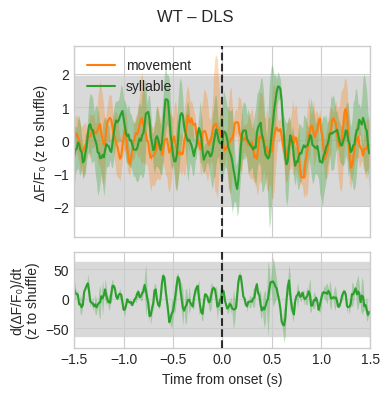


=== Processing: WT - DMS ===
Found 7 sessions for genotype 'WT'
Extracting snippets for area 'DMS'...


Extracting:   0%|          | 0/7 [00:00<?, ?it/s]

Normalizing snippets (Datta Style)...


Running Shuffle...
Preparing data for Memmap...


Writing Memmap to /home/fsp585/Desktop/FiberphotometryCode/syllable_generation/analysis/replications/datta/processing/1f_cache/temp_memmap_matrix.npy (Watch this file grow)...
Dispatching 200 jobs (backend=loky, n_jobs=-1)...


Bootstrapping:   0%|          | 0/200 [00:00<?, ?it/s]

Cleaned up memmap file.


Saving stats to stats_WT_DMS_opt.pkl...


Result: WT - DMS


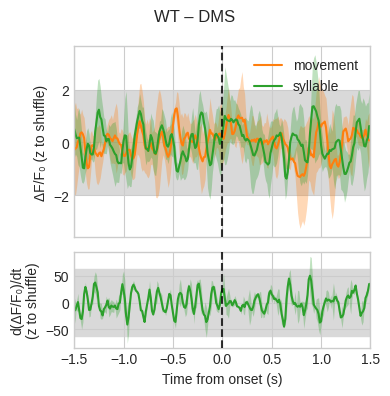


=== Processing: KI - DLS ===
Found 8 sessions for genotype 'KI'
Extracting snippets for area 'DLS'...


Extracting:   0%|          | 0/8 [00:00<?, ?it/s]

Normalizing snippets (Datta Style)...


Running Shuffle...
Preparing data for Memmap...


Writing Memmap to /home/fsp585/Desktop/FiberphotometryCode/syllable_generation/analysis/replications/datta/processing/1f_cache/temp_memmap_matrix.npy (Watch this file grow)...
Dispatching 200 jobs (backend=loky, n_jobs=-1)...


Bootstrapping:   0%|          | 0/200 [00:00<?, ?it/s]

Cleaned up memmap file.


Saving stats to stats_KI_DLS_opt.pkl...


Result: KI - DLS


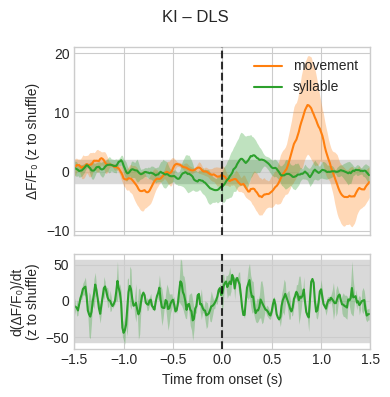


=== Processing: KI - DMS ===
Found 8 sessions for genotype 'KI'
Extracting snippets for area 'DMS'...


Extracting:   0%|          | 0/8 [00:00<?, ?it/s]

Normalizing snippets (Datta Style)...


Running Shuffle...
Preparing data for Memmap...


Writing Memmap to /home/fsp585/Desktop/FiberphotometryCode/syllable_generation/analysis/replications/datta/processing/1f_cache/temp_memmap_matrix.npy (Watch this file grow)...
Dispatching 200 jobs (backend=loky, n_jobs=-1)...


Bootstrapping:   0%|          | 0/200 [00:00<?, ?it/s]

Cleaned up memmap file.


Saving stats to stats_KI_DMS_opt.pkl...


Result: KI - DMS


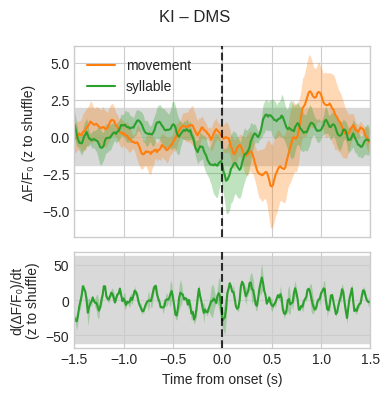


All combinations processed.


In [4]:
# === CONFIG ===
genotypes = ["WT", "KI"]
areas = ["DLS", "DMS"]
FS = 80.0

results = {}

for geno in genotypes:
    for area in areas:
        
        # Run the single-combo processor
        # This extracts, computes, saves, and then DELETES the heavy data
        res = process_and_plot_single_combo(
            sessions,
            genotype=geno,
            area=area,
            fs=FS,
            pre_s=-10.0,
            post_s=10.0,
            n_shuffles=200,
            random_state=0
        )
        
        if res[0] is not None:
            fig, stats, z = res
            results[(geno, area)] = (fig, stats, z)
            
            # Display immediately so you see progress
            print(f"Result: {geno} - {area}")
            display(fig)
            plt.close(fig) # Close plot to free matplotlib memory
            
        # Force Garbage Collection between iterations
        gc.collect()

print("\nAll combinations processed.")